# A3 climate indicators: what each month is usually like in each LGA

For every LGA and calendar month, from 1981 (2000 for IMERG, 2015 for SMAP) to 2025: the long-term mean of each monthly value, and the share of years in which the month held at least one event day. These feed the pattern panel on the Season screen (F3e): heat stress, frost, extreme rain, soil moisture, evaporation.

Heat day: Tmax at or above 35 C (maize pollination risk). Frost day: Tmin at or below 2 C. Both are counted daily from POWER in `data/power_kaduna.py`. Settings: `config/models.yaml` (`climate_indicators`). Formulas: `model/indicators.py`.

## Imports

In [1]:
# Third-party libraries only. Project code is imported two cells down, after the path
# setup, so this cell runs in any fresh kernel.
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

In [2]:
# Path setup: makes the notebook work whether Jupyter starts in notebooks/ or the repo
# root, and lets `import model` find the project package.
# Run from notebooks/ or the repo root: config paths are relative to the repo root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [3]:
# Project code: the tested functions in model/. The notebook calls them; it never
# redefines them, so its results match `python -m model.build` exactly.
from model import indicators as ind
from model.io import write_csv
from model.settings import load_model_config

## 1. Load the monthly features

In [4]:
# Load the LGA-month features and keep 1981 to 2025, then count how many values each event
# and SMAP column has (IMERG starts in 2000, SMAP in 2015).
# Scope: all 23 Kaduna LGAs.
cfg = load_model_config()
ci = cfg.climate_indicators
month = pd.read_parquet(cfg.paths.monthly_features)
month = month[month["year"].between(ci.years.start, ci.years.end)]
month[list(ci.events.values()) + ["smap_anomaly_z"]].count()

power_heat_days           12420
power_cold_days           12420
chirps_heavy_days_50mm    12420
imerg_extreme_days_p95     7728
smap_anomaly_z             2990
dtype: int64

## 2. Build the indicator table for all 23 LGAs (Zaria shown first as an example)

In [5]:
# Build the table: for each LGA and calendar month, the long-term mean of each value and
# the share of years with at least one event day. Zaria is printed as an example.
table = ind.indicator_table(month, ci.means, ci.events, ci.smap_dry_z)
table[table["lga"] == "Zaria"].set_index("month")[
    [
        "power_heat_days_mean",
        "heat_share_years",
        "frost_share_years",
        "very_heavy_rain_50mm_share_years",
        "extreme_rain_p95_share_years",
        "soil_dry_share_years",
        "power_et0_pm_mm_mean",
    ]
].round(2)

,power_heat_days_mean,heat_share_years,frost_share_years,very_heavy_rain_50mm_share_years,extreme_rain_p95_share_years,soil_dry_share_years,power_et0_pm_mm_mean
month,,,,,,,
1,0.80,0.16,0.0,0.00,0.0,0.1,192.56
2,5.02,0.64,0.0,0.00,0.0,0.0,202.30
3,14.91,1.00,0.0,0.00,0.0,0.0,226.59
4,15.73,0.98,0.0,0.00,0.035714,0.090909,196.99
5,6.89,0.73,0.0,0.04,0.321429,0.090909,170.75
6,1.31,0.29,0.0,0.00,0.5,0.090909,140.41
7,0.16,0.04,0.0,0.04,0.821429,0.181818,128.07
8,0.00,0.00,0.0,0.07,0.892857,0.181818,116.79
9,0.00,0.00,0.0,0.04,0.714286,0.0,123.53


{'LGAs': 23, 'rows (LGA x month)': 276}

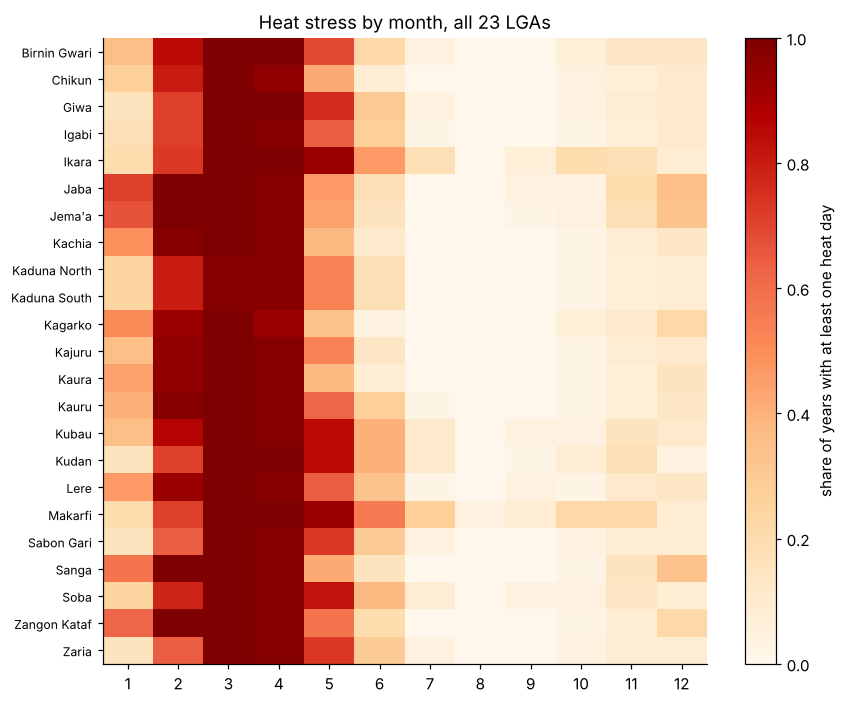

In [6]:
# All 23 LGAs: share of years with at least one heat day (Tmax at or above 35 C), by month.
heat = table.pivot(index="lga", columns="month", values="heat_share_years")
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(heat, cmap="OrRd", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(12), range(1, 13))
ax.set_yticks(range(len(heat)), heat.index, fontsize=8)
fig.colorbar(im, label="share of years with at least one heat day")
ax.set_title("Heat stress by month, all 23 LGAs")
plt.tight_layout()
{"LGAs": table["lga"].nunique(), "rows (LGA x month)": len(table)}

## 3. The year at a glance, statewide

{'frost days in the whole record': 0}

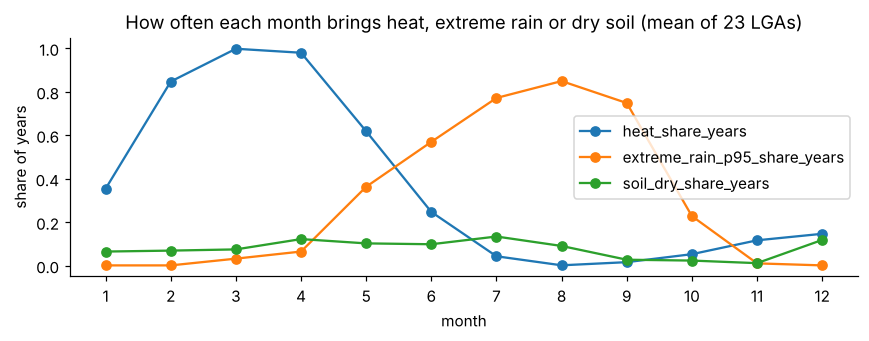

In [7]:
# Statewide year at a glance: heat, extreme rain and dry soil by month, averaged over the
# 23 LGAs. Frost is counted over the whole record to confirm it never occurs.
statewide = table.groupby("month")[
    ["heat_share_years", "extreme_rain_p95_share_years", "soil_dry_share_years"]
].mean()
ax = statewide.plot(marker="o", figsize=(8, 3.2))
ax.set_xticks(range(1, 13))
ax.set_ylabel("share of years")
ax.set_title("How often each month brings heat, extreme rain or dry soil (mean of 23 LGAs)")
plt.tight_layout()
{"frost days in the whole record": int(month["power_cold_days"].sum())}

Heat stress is a dry-season risk (February to May, before the rains), extreme rain peaks in July and August, and frost never happens: the PRD shows frost as "very low" rather than hiding it.

## 4. Save

In [8]:
# Write the A3 table (23 LGAs x 12 months) for the app.
write_csv(table, cfg.paths.output_dir / "a3" / "a3_lga_month_indicators.csv")

PosixPath('data/processed/models/a3/a3_lga_month_indicators.csv')